# FF2: Fingerprinting bei gesperrten Cookies

Wie verändert sich die Anzahl der Fingerprinting-Aufrufe, wenn der Browser das Setzen von Cookies blockiert? Hypothese H2: Sind Third-Party-Cookies gesperrt, steigt die Anzahl der Third-Party-Fingerprinting-Aufrufe.

# Vorbereitung

- Setzen der Projektwurzel auf Workspace-Root
- Einlesen der Daten (je Bedingung eine Datei)

In [1]:
# Projektwurzel = erster Ordner nach oben mit pyproject.toml
# Pfade gelten ab Wurzel
import os
import sys
from pathlib import Path

ROOT = next(ordner for ordner in [Path.cwd(), *Path.cwd().parents] if (ordner / "pyproject.toml").exists())
os.chdir(ROOT)
# Importe aus dem Repo möglich machen
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Projektwurzel:", ROOT)

Projektwurzel: /home/bhartl/Uni/Bachelor/BachelorArbeit/Fingerprinting-Crawler


In [2]:
# Rohdaten einlesen: je Bedingung eine JSONL-Datei, jede Zeile ein JSON-Objekt
# Konfigurationszeilen (eine je Start des Crawlers, erkennbar an path_to_output) getrennt von den Messzeilen halten
import json

ORDNER = Path("results/Forschungsfrage 2")
# Bedingung -> Datei, Reihenfolge wie in der Thesis (Bedingung 1 bis 3)
DATEIEN = {
    "alles_erlaubt": ORDNER / "ff2_alles_erlaubt.jsonl",
    "nur_cdp": ORDNER / "ff2_nur_cdp.jsonl",
    "alles_geblockt": ORDNER / "ff2_alles_geblockt.jsonl",
}
BEDINGUNGEN = list(DATEIEN)
# Kurze Namen für Achsen und Tabellen
KURZ = {"alles_erlaubt": "keine Sperre", "nur_cdp": "Browser", "alles_geblockt": "Browser + JS"}

configs = {} # Bedingung -> Liste der Konfigurationszeilen (eine je Start des Crawlers)
zeilen = {}  # Bedingung -> Liste der Messzeilen
for name, pfad in DATEIEN.items():
    configs[name], zeilen[name] = [], []
    with open(pfad, encoding="utf-8") as datei:
        for line in datei:
            if not line.strip():
                continue
            zeile = json.loads(line)
            (configs[name] if "path_to_output" in zeile else zeilen[name]).append(zeile)
    n_websites = len({zeile["website"] for zeile in zeilen[name]})
    print(f"{name}: {len(configs[name])} Konfigurationszeilen, {len(zeilen[name])} Messzeilen, {n_websites} Websites")

alles_erlaubt: 13 Konfigurationszeilen, 3721 Messzeilen, 1000 Websites
nur_cdp: 13 Konfigurationszeilen, 3716 Messzeilen, 1000 Websites
alles_geblockt: 13 Konfigurationszeilen, 3725 Messzeilen, 1000 Websites


# Verarbeitung

- Je Website und Bedingung nur die letzte gültige Messung
- Konfiguration prüfen: alle Starts mit denselben Einstellungen, Bedingungen unterscheiden sich nur in der Sperre
- Vollständige Websites: in allen drei Bedingungen gemessen
- Fehlerhafte Websites aus dem Panel nehmen: HTTP-Fehler, Fehler- oder Bot-Seite, Weiterleitung auf fremde Domain, leerer Titel (an beiden Messpunkten)

In [3]:
# Je (Website, Bedingung) nur die letzte gültige Zeile behalten. Mehrere Zeilen entstehen durch Fehler und Wiederholung
# Gültig = success und internet_ok, wie beim Fortsetzen des Crawlers (core/logging.py, done_crawls)
from collections import Counter

def gueltig(zeile):
    return zeile["success"] and zeile["internet_ok"]

def art(zeile):
    if not gueltig(zeile):
        return "fehler"
    if "stats_vor_consent" in zeile:
        return "gemessen"
    return "unbekannt"

letzte = {}
for bedingung in BEDINGUNGEN:
    letzte[bedingung] = {}
    # Reihenfolge der Datei = Reihenfolge der Messung: spätere Zeile ersetzt frühere
    for zeile in zeilen[bedingung]:
        bisher = letzte[bedingung].get(zeile["website"])
        # Gültige Zeile ersetzt alles, Fehlerzeile nur eine Fehlerzeile
        if bisher is None or gueltig(zeile) or not gueltig(bisher):
            letzte[bedingung][zeile["website"]] = zeile
    print(f"{bedingung}: {len(zeilen[bedingung])} Zeilen -> {len(letzte[bedingung])} Websites", dict(Counter(art(zeile) for zeile in letzte[bedingung].values())))

alles_erlaubt: 3721 Zeilen -> 1000 Websites {'gemessen': 761, 'fehler': 239}
nur_cdp: 3716 Zeilen -> 1000 Websites {'gemessen': 761, 'fehler': 239}
alles_geblockt: 3725 Zeilen -> 1000 Websites {'gemessen': 761, 'fehler': 239}


In [4]:
# Konfiguration prüfen: alle Starts einer Bedingung mit denselben Werten, sonst passen die Zeilen nicht zusammen
# Die Bedingungen dürfen sich nur in allow_3p (Browser-Sperre) und js_cookie_block (JS-Sperre) unterscheiden
import pandas as pd

FELDER = ["allow_3p", "js_cookie_block", "consent", "loading_time", "visit_time_after_consent", "site_timeout", "batch_size", "batch_seed"]
for bedingung in BEDINGUNGEN:
    assert all(config[feld] == configs[bedingung][-1][feld] for config in configs[bedingung] for feld in FELDER), bedingung
pd.DataFrame({bedingung: {feld: configs[bedingung][-1][feld] for feld in FELDER} for bedingung in BEDINGUNGEN})

,alles_erlaubt,nur_cdp,alles_geblockt
allow_3p,True,False,False
js_cookie_block,False,False,True
consent,True,True,True
loading_time,10,10,10
visit_time_after_consent,10,10,10
site_timeout,90,90,90
batch_size,1000,1000,1000
batch_seed,1,1,1


In [5]:
# Vollständig = in allen drei Bedingungen gemessen. Nur so vergleicht man dieselbe Website mit und ohne Sperre
websites = sorted(set().union(*(letzte[bedingung] for bedingung in BEDINGUNGEN)))
vollstaendig = [website for website in websites
                if all(website in letzte[bedingung] and art(letzte[bedingung][website]) == "gemessen" for bedingung in BEDINGUNGEN)]
print(f"{len(websites)} Websites: {len(vollstaendig)} vollständig, {len(websites) - len(vollstaendig)} unvollständig")

1000 Websites: 759 vollständig, 241 unvollständig


In [6]:
# Messung an beiden Messpunkten prüfen. Ein Problem in einer Bedingung nimmt die ganze Website aus dem Panel
# Fehler- oder Bot-Seite am Titel erkennen: Bot-Sperre, HTTP-Fehlerseite, Domain zu verkaufen oder nur reserviert
import re

FEHLERTITEL = re.compile(r"just a moment|captcha|attention required|access denied|forbidden|^404|not found|error page"
                         r"|is for sale|hugedomains|réservé|a bien été créé|nom de domaine déposé", re.IGNORECASE)

def probleme(website, bedingung):
    zeile = letzte[bedingung][website]
    gefunden = set()
    # HTTP-Fehler der Startseite, z. B. 403 bei einer Bot-Sperre
    if (zeile["stats_vor_consent"].get("status") or 0) >= 400:
        gefunden.add("HTTP-Fehler")
    for punkt in ("stats_vor_consent", "stats_nach_consent"):
        stats = zeile[punkt]
        titel = stats["title"].strip()
        if not titel:
            gefunden.add("leerer Titel")
        elif FEHLERTITEL.search(titel):
            gefunden.add("Fehler- oder Bot-Seite")
        # Weiterleitung auf fremde Domain: deren Skripte und Cookies zählen sonst als 3P (vgl. Kontrolle der Sperren in der Thesis)
        if stats["cross_domain_redirect"]:
            gefunden.add("Weiterleitung fremde Domain")
    return gefunden

# Website -> Gründe über alle Bedingungen
fehlerhaft = {}
for website in vollstaendig:
    gruende = set().union(*(probleme(website, bedingung) for bedingung in BEDINGUNGEN))
    if gruende:
        fehlerhaft[website] = sorted(gruende)
panel = [website for website in vollstaendig if website not in fehlerhaft]
print(f"{len(vollstaendig)} vollständig -> {len(fehlerhaft)} fehlerhaft, {len(panel)} im Panel")
print("Gründe (eine Website kann mehrere haben):", dict(Counter(grund for gruende in fehlerhaft.values() for grund in gruende)))
# Zum Prüfen von Hand: Titel, die als Fehler- oder Bot-Seite gelten
treffer = Counter(letzte[bedingung][website][punkt]["title"].strip()[:80] for website in vollstaendig for bedingung in BEDINGUNGEN
                  for punkt in ("stats_vor_consent", "stats_nach_consent") if FEHLERTITEL.search(letzte[bedingung][website][punkt]["title"]))
for titel, anzahl in treffer.most_common():
    print(f"  {anzahl:2d} x {titel}")

759 vollständig -> 181 fehlerhaft, 578 im Panel
Gründe (eine Website kann mehrere haben): {'Weiterleitung fremde Domain': 93, 'Fehler- oder Bot-Seite': 17, 'HTTP-Fehler': 73, 'leerer Titel': 27}
  30 x Error 404 (Not Found)!!1
  20 x Access Denied
  18 x Attention Required! | Cloudflare
   6 x 403 Forbidden
   6 x Error Page | eBay
   6 x Bravo ! Votre domaine lwsdns.com a bien été créé avec Hebergeur-Discount !
   6 x 404 Not Found
   6 x Vonetize.com is for sale


**Panel**
- 1000 Websites, 759 in allen drei Bedingungen gemessen, 578 ohne Fehler im Panel
- Häufigster Grund: Weiterleitung auf eine fremde Domain (93), dann HTTP-Fehler wie 403 oder 404 (73)
- FF2 lief mit 1000 Websites, die Thesis spricht von 500 für alle Messreihen: Text anpassen oder auf die FF1-Stichprobe beschränken (siehe Robustheit)

# DataFrames

- snap: eine Zeile je Website und Bedingung mit Panel, Reihenfolge des Besuchs, Banner-Klick, Cookies, Titel, Screenshot
- Wertung der Methoden nach Tabelle tab:Schnittstellen (live: devicePixelRatio zählt mit, Storage zählt nicht als FP)
- calls: Aufrufe je Bedingung, Messpunkt, Methode, Partei und Quelle

In [7]:
# snap: eine Zeile je Website und Bedingung. Für die Kontrolle der Sperren, die Reihenfolge und die Screenshot-Sichtung
# Die Aufrufe stehen in calls
PUNKTE = {"vor": "stats_vor_consent", "nach": "stats_nach_consent"}
panel_menge = set(panel)

snap_zeilen = []
for bedingung in BEDINGUNGEN:
    for website, zeile in letzte[bedingung].items():
        eintrag = {"bedingung": bedingung, "website": website, "art": art(zeile), "im_panel": website in panel_menge}
        if eintrag["art"] == "gemessen":
            nach = zeile["stats_nach_consent"] or {}
            eintrag |= {"crawl_time": zeile["crawl_time"], "consent_klick": bool(nach.get("consent_ok")),
                        "consent_gespeichert": bool((nach.get("consent_check") or {}).get("consent_storage_changed"))}
            for punkt, key in PUNKTE.items():
                stats = zeile[key] or {}
                eintrag |= {
                    f"cookies_1p_{punkt}": stats.get("n_cookies_1p"),
                    f"cookies_3p_{punkt}": stats.get("n_cookies_3p"),
                    # Domains mit 3P-Cookies: ohne und mit Partitionierung (partitionierte erlaubt die Browser-Sperre weiter)
                    f"cookie_quellen_3p_{punkt}": len(stats.get("cookie_sources_3p", [])),
                    f"cookie_quellen_partitioniert_{punkt}": len(stats.get("cookie_sources_partitioned", [])),
                    f"titel_{punkt}": stats.get("title"),
                    f"screenshot_{punkt}": stats.get("screenshot"),
                }
        snap_zeilen.append(eintrag)

snap = pd.DataFrame(snap_zeilen)
snap["crawl_time"] = pd.to_datetime(snap["crawl_time"])
# Reihenfolge der drei Besuche einer Website (1 = zuerst). Wechselt reihum, damit sich Reihenfolgeeffekte ausgleichen
snap["position"] = snap.groupby("website")["crawl_time"].rank(method="first")
print(len(snap), "Zeilen")
pd.crosstab(snap["bedingung"], snap["art"]).loc[BEDINGUNGEN]

3000 Zeilen


art,fehler,gemessen
bedingung,,
alles_erlaubt,239,761
nur_cdp,239,761
alles_geblockt,239,761


In [8]:
import pandas as pd

# Wertung der Methoden wie Tabelle tab:Schnittstellen der Thesis. Schlüssel "api.method" wie in events, nicht nur api:
# getBattery hat api "Navigator", gehört aber zu Gerät. getImageData (stark) und measureText (schwach) haben beide api "canvas2D"
METHODEN = pd.DataFrame([
    ("canvas.toDataURL", "Canvas", "stark"),
    ("canvas.toBlob", "Canvas", "stark"),
    ("canvas2D.getImageData", "Canvas", "stark"),
    ("canvas2D.measureText", "Canvas", "schwach"),
    ("canvas2D.isPointInPath", "Canvas", "schwach"),
    ("WebGL.getParameter", "WebGL", "stark"),
    ("WebGL.getSupportedExtensions", "WebGL", "stark"),
    ("WebGL.readPixels", "WebGL", "stark"),
    ("audio.getChannelData", "Audio", "stark"),
    ("webaudio.OfflineAudioContext", "Audio", "stark"),
    ("webaudio.AudioContext", "Audio", "schwach"),
    ("Navigator.userAgent", "Browser", "schwach"),
    ("Navigator.userAgentData", "Browser", "schwach"),
    ("NavigatorUAData.getHighEntropyValues", "Browser", "schwach"),
    ("Navigator.platform", "Browser", "schwach"),
    ("Navigator.plugins", "Browser", "schwach"),
    ("Navigator.language", "Browser", "schwach"),
    ("Navigator.languages", "Browser", "schwach"),
    ("Navigator.cookieEnabled", "Browser", "schwach"),
    ("Navigator.doNotTrack", "Browser", "schwach"),
    ("DateTimeFormat.resolvedOptions", "Browser", "schwach"),
    ("Screen.width", "Bildschirm", "schwach"),
    ("Screen.height", "Bildschirm", "schwach"),
    ("Screen.colorDepth", "Bildschirm", "schwach"),
    ("Window.devicePixelRatio", "Bildschirm", "schwach"),
    ("Navigator.getBattery", "Gerät", "schwach"),
    ("MediaDevices.enumerateDevices", "Gerät", "schwach"),
    ("SpeechSynthesis.getVoices", "Gerät", "schwach"),
    ("StorageManager.estimate", "Gerät", "schwach"),
    ("local/session storage.getItem", "Storage", "kein FP"),
    ("local/session storage.setItem", "Storage", "kein FP"),
], columns=["methode", "kategorie", "wertung"])
# Live gibt es kein Archiv: devicePixelRatio ist messbar und zählt. Storage ist kein FP, bleibt aber für die Frage nach dem Ausweichen drin
METHODEN["zaehlt"] = METHODEN["wertung"] != "kein FP"
METHODEN

,methode,kategorie,wertung,zaehlt
0,canvas.toDataURL,Canvas,stark,True
1,canvas.toBlob,Canvas,stark,True
2,canvas2D.getImageData,Canvas,stark,True
3,canvas2D.measureText,Canvas,schwach,True
4,canvas2D.isPointInPath,Canvas,schwach,True
5,WebGL.getParameter,WebGL,stark,True
6,WebGL.getSupportedExtensions,WebGL,stark,True
7,WebGL.readPixels,WebGL,stark,True
8,audio.getChannelData,Audio,stark,True
9,webaudio.OfflineAudioContext,Audio,stark,True


In [9]:
# calls: Aufrufe je Bedingung, Messpunkt, Methode, Partei und Quelle, gebaut aus events
# events wächst nur an: die Aufrufe eines Messpunkts sind die ersten n_fp_calls Einträge (Messpunkt nach ist kumulativ)
from functools import lru_cache
from utils.origin_domain import origin_domain

@lru_cache(maxsize=None)
def domain_von(host):
    # Quelle als eTLD+1 wie im Crawler, 1P-Aufrufe haben keinen Host
    return origin_domain(host) if host else ""

call_zeilen = []
for bedingung in BEDINGUNGEN:
    for website, zeile in letzte[bedingung].items():
        if art(zeile) != "gemessen":
            continue
        for punkt, key in PUNKTE.items():
            stats = zeile[key]
            if not stats:
                continue
            zaehler = Counter()
            for event in zeile["events"][:stats["n_fp_calls"]]:
                # third_party: True, False oder "Keine py_url" (Zuordnung im Browser nicht möglich)
                partei = {True: "3P", False: "1P"}.get(event["third_party"], "unbekannt")
                zaehler[(f"{event['api']}.{event['method']}", partei, domain_von(event["script_url"]))] += 1
            # Gegenprobe je Messpunkt: 3P-Aufrufe je api aus den ersten n_fp_calls events == fp_calls_per_api_3p des Crawlers
            api_3p = Counter()
            for (methode, partei, _), anzahl in zaehler.items():
                if partei == "3P":
                    api_3p[methode.rpartition(".")[0]] += anzahl
            assert dict(api_3p) == stats["fp_calls_per_api_3p"], (website, bedingung, punkt)
            for (methode, partei, quelle_domain), anzahl in zaehler.items():
                call_zeilen.append({"bedingung": bedingung, "website": website, "punkt": punkt, "methode": methode,
                                    "partei": partei, "quelle": quelle_domain, "anzahl": anzahl})

calls = pd.DataFrame(call_zeilen).merge(METHODEN, on="methode", how="left", validate="many_to_one")
# Jede Methode braucht eine Wertung, sonst fehlt sie in METHODEN
assert calls["kategorie"].notna().all(), sorted(calls.loc[calls["kategorie"].isna(), "methode"].unique())
print(len(calls), "Zeilen")
calls.groupby(["bedingung", "punkt", "partei"])["anzahl"].sum().unstack().loc[BEDINGUNGEN]

141824 Zeilen


partei                    1P      3P
bedingung      punkt                
alles_erlaubt  nach   110183  489695
               vor     80355  246747
nur_cdp        nach   111306  453956
               vor     82062  232237
alles_geblockt nach   104734  402715
               vor     80738  240651

# Analyse

Hauptmesspunkt ist nach Consent (in allen Bedingungen wird zugestimmt). Gezählt werden nur 3P-Aufrufe von Methoden, die als Fingerprinting zählen.

- Kontrolle der Sperren: wirken sie wie in Tabelle tab:Cookie-Sperren?
- Aufrufe je Bedingung: Verteilung über die Websites
- Website für Website: mit Sperre mehr oder weniger Aufrufe?
- Techniken: Veränderung je Methode
- Anbieter: Quellen mit mehr bzw. weniger Aufrufen unter Sperre
- Ausweichen auf den Speicher (localStorage, sessionStorage)
- Reihenfolge der Besuche und Consent je Bedingung

In [10]:
# Stil und Export für die Thesis: SVG mit Text als Text, LaTeX setzt die Beschriftung in der Schrift der Arbeit (vgl. analysis/abbildungen.md)
# In LaTeX: {\footnotesize \includesvg[width=\textwidth]{figures/ff2/<name>}}, übersetzen mit -shell-escape
import matplotlib.pyplot as plt

plt.rcParams.update({
    "svg.fonttype": "none", # Text bleibt Text, sonst werden Buchstaben zu Pfaden
    "axes.unicode_minus": False, # normales Minus, pdfLaTeX kennt das Unicode-Minus nicht
    "font.size": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.spines.top": False, "axes.spines.right": False,
})
BREITE = 135 / 25.4 # \textwidth der Thesis = 135 mm, in Zoll
ABBILDUNGEN = ROOT.parent / "Fingerprinting-Bachelor" / "figures" / "ff2"
# Keine LaTeX-Sonderzeichen (% _ & #) in Beschriftungen, deshalb "in Prozent" statt "%"

def speichern(fig, name):
    ABBILDUNGEN.mkdir(parents=True, exist_ok=True)
    fig.savefig(ABBILDUNGEN / f"{name}.svg")

# Eine Farbe je Bedingung in allen Abbildungen
FARBEN = {"alles_erlaubt": "0.55", "nur_cdp": "C0", "alles_geblockt": "C3"}

from matplotlib.ticker import FuncFormatter, NullFormatter

def zahlenachse(achse):
    # Log-Achse mit ganzen Zahlen (1, 10, 100, 1.000) statt 10 hoch x: Hochzahlen aus der SVG setzt LaTeX sonst als normale Ziffern
    achse.set_major_formatter(FuncFormatter(lambda wert, _: f"{wert:,.0f}".replace(",", ".")))
    achse.set_minor_formatter(NullFormatter())

In [11]:
# Grundlage für alle Auswertungen: Panel, nur 3P, nur Methoden, die zählen. Jede Panel-Website zählt, auch ohne Aufruf (dann 0)
auswahl = calls[calls["website"].isin(panel_menge) & (calls["partei"] == "3P") & calls["zaehlt"]]
summen = (auswahl.assign(stark=auswahl["wertung"] == "stark")
          .groupby(["bedingung", "website", "punkt"], as_index=False).agg(anzahl=("anzahl", "sum"), stark=("stark", "any")))
basis = snap.loc[snap["im_panel"], ["bedingung", "website", "position"]].merge(pd.DataFrame({"punkt": ["vor", "nach"]}), how="cross")
je_website = basis.merge(summen, on=["bedingung", "website", "punkt"], how="left").fillna({"anzahl": 0, "stark": False}).astype({"stark": bool})

# Tabellen Website x Bedingung am Hauptmesspunkt nach Consent
nach = je_website[je_website["punkt"] == "nach"]
aufrufe = nach.pivot(index="website", columns="bedingung", values="anzahl")[BEDINGUNGEN]
stark = nach.pivot(index="website", columns="bedingung", values="stark")[BEDINGUNGEN]
print(len(aufrufe), "Websites im Panel")
je_website.groupby(["punkt", "bedingung"])["anzahl"].agg(["median", "mean"]).round(1)

578 Websites im Panel


median   mean
punkt bedingung                    
nach  alles_erlaubt    154.5  436.0
      alles_geblockt   141.0  386.3
      nur_cdp          154.0  442.2
vor   alles_erlaubt     96.5  229.9
      alles_geblockt    97.0  216.9
      nur_cdp           97.5  223.5

**Grundlage**
- 578 Websites, je Bedingung ein Besuch, Hauptmesspunkt nach Consent
- Median der 3P-Aufrufe je Website: 154,5 (keine Sperre), 154 (Browser), 141 (Browser + JS)

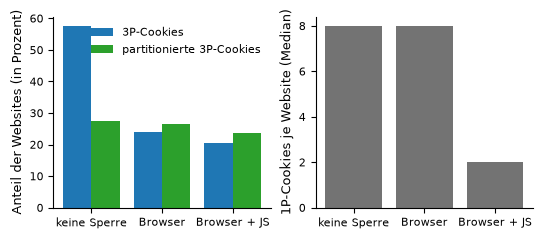

Trotz Browser-Sperre: [('criteo.com', 53), ('doubleclick.net', 52), ('casalemedia.com', 33), ('adform.net', 27), ('adsrvr.org', 26), ('rubiconproject.com', 25), ('adnxs.com', 24), ('yahoo.com', 24)]


,mit_3p_cookies,mit_partitionierten,median_1p_cookies
bedingung,,,
alles_erlaubt,57.6,27.3,8.0
nur_cdp,23.9,26.6,8.0
alles_geblockt,20.6,23.5,2.0


In [12]:
# Kontrolle der Sperren (nach Consent): wirken sie wie in Tabelle tab:Cookie-Sperren?
# Browser-Sperre: Drittanbieter dürfen nur noch partitionierte Cookies setzen. JS-Sperre: weniger 1P-Cookies, weil fremde Skripte keine mehr schreiben
kontrolle = snap[snap["im_panel"]].groupby("bedingung").agg(
    mit_3p_cookies=("cookie_quellen_3p_nach", lambda x: (x > 0).mean() * 100),
    mit_partitionierten=("cookie_quellen_partitioniert_nach", lambda x: (x > 0).mean() * 100),
    median_1p_cookies=("cookies_1p_nach", "median")).loc[BEDINGUNGEN]

fig, achsen = plt.subplots(1, 2, figsize=(BREITE, BREITE * 0.42), layout="constrained")
x = range(len(BEDINGUNGEN))
achsen[0].bar([i - 0.2 for i in x], kontrolle["mit_3p_cookies"], width=0.4, color="C0", label="3P-Cookies")
achsen[0].bar([i + 0.2 for i in x], kontrolle["mit_partitionierten"], width=0.4, color="C2", label="partitionierte 3P-Cookies")
achsen[0].set_ylabel("Anteil der Websites (in Prozent)")
achsen[0].legend(frameon=False)
achsen[1].bar(x, kontrolle["median_1p_cookies"], color="0.45")
achsen[1].set_ylabel("1P-Cookies je Website (Median)")
for ax in achsen:
    ax.set_xticks(list(x), [KURZ[bedingung] for bedingung in BEDINGUNGEN])
speichern(fig, "kontrolle_sperren")
plt.show()
# Welche 3P-Cookies kommen trotz Browser-Sperre an? Domain und Anzahl der Websites
print("Trotz Browser-Sperre:", Counter(domain for website in panel for domain in letzte["nur_cdp"][website]["stats_nach_consent"]["cookie_sources_3p"]).most_common(8))
kontrolle.round(1)

**Kontrolle der Sperren**
- Die Browser-Sperre senkt den Anteil der Websites mit 3P-Cookies von 57,6 % auf 23,9 %, mit JS-Sperre auf 20,6 %
- Partitionierte 3P-Cookies bleiben wie erwartet (27 % bis 24 %)
- Die JS-Sperre wirkt: 1P-Cookies im Median 2 statt 8
- Aber: Auf rund jeder vierten Website kommen trotz Browser-Sperre klassische Werbe-Cookies an (criteo.com, doubleclick.net, casalemedia.com). Laut Thesis dürfte es keine geben. Vermutung: In Werbe-Iframes, die Chromium als eigenen Prozess lädt, greift die per CDP gesetzte Sperre nicht. Prüfen und unter Grenzen nennen

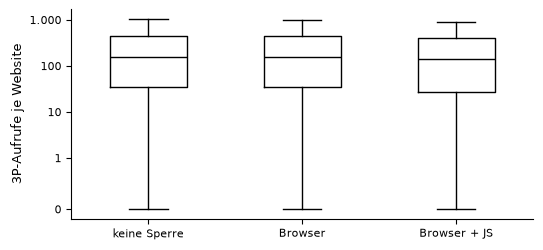

bedingung,alles_erlaubt,nur_cdp,alles_geblockt
mean,436.0,442.2,386.3
25%,35.5,35.5,27.5
50%,154.5,154.0,141.0
75%,449.5,442.5,395.2


In [13]:
# Aufrufe je Bedingung: Verteilung der 3P-Aufrufe je Website (nach Consent). Box = mittlere 50 %, Strich = Median
# Log-Achse, weil sich die Websites um Größenordnungen unterscheiden. symlog zeigt auch Websites ohne Aufruf (0)
fig, ax = plt.subplots(figsize=(BREITE, BREITE * 0.45), layout="constrained")
ax.boxplot([aufrufe[bedingung] for bedingung in BEDINGUNGEN], tick_labels=[KURZ[bedingung] for bedingung in BEDINGUNGEN],
           showfliers=False, widths=0.5, medianprops={"color": "black"})
ax.set_yscale("symlog", linthresh=1)
zahlenachse(ax.yaxis)
ax.set_ylabel("3P-Aufrufe je Website")
speichern(fig, "aufrufe_je_bedingung")
plt.show()
aufrufe.describe(percentiles=[0.25, 0.5, 0.75]).loc[["mean", "25%", "50%", "75%"]].round(1)

**Aufrufe je Bedingung**
- Die Verteilungen sind fast gleich: Median 154,5 / 154 / 141, mittlere 50 % liegen übereinander
- Mit Browser + JS-Sperre eher etwas weniger, nicht mehr

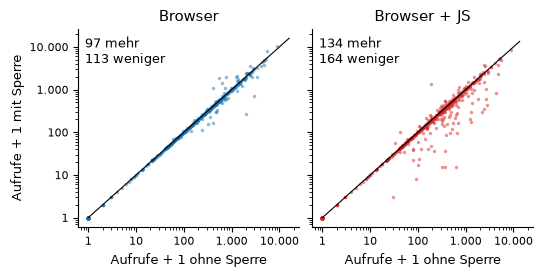

Browser: mehr 17%, weniger 20%, gleich 64%, Faktor im Median 1.00
Browser + JS: mehr 23%, weniger 28%, gleich 48%, Faktor im Median 1.00


In [14]:
# Website für Website: x = Aufrufe ohne Sperre, y = Aufrufe mit Sperre. Punkte über der Diagonale = mehr Aufrufe mit Sperre
# +1, damit Websites ohne Aufruf auf der Log-Achse erscheinen
fig, achsen = plt.subplots(1, 2, figsize=(BREITE, BREITE * 0.5), layout="constrained", sharex=True, sharey=True)
for ax, bedingung in zip(achsen, BEDINGUNGEN[1:]):
    x, y = aufrufe["alles_erlaubt"] + 1, aufrufe[bedingung] + 1
    ax.scatter(x, y, s=6, alpha=0.5, color=FARBEN[bedingung], linewidths=0)
    grenze = max(x.max(), y.max()) * 1.5
    ax.plot([1, grenze], [1, grenze], color="black", linewidth=0.8)
    ax.set_xscale("log")
    ax.set_yscale("log")
    zahlenachse(ax.xaxis)
    zahlenachse(ax.yaxis)
    ax.set_title(KURZ[bedingung])
    ax.text(0.03, 0.97, f"{(y > x).sum()} mehr\n{(y < x).sum()} weniger", transform=ax.transAxes, va="top")
    ax.set_xlabel("Aufrufe + 1 ohne Sperre")
achsen[0].set_ylabel("Aufrufe + 1 mit Sperre")
speichern(fig, "website_vergleich")
plt.show()
# Veränderung je Website als Faktor (Median): 1 = gleich, über 1 = mehr mit Sperre
for bedingung in BEDINGUNGEN[1:]:
    faktor = ((aufrufe[bedingung] + 1) / (aufrufe["alles_erlaubt"] + 1)).median()
    print(f"{KURZ[bedingung]}: mehr {(aufrufe[bedingung] > aufrufe['alles_erlaubt']).mean():.0%}, weniger {(aufrufe[bedingung] < aufrufe['alles_erlaubt']).mean():.0%}, "
          f"gleich {(aufrufe[bedingung] == aufrufe['alles_erlaubt']).mean():.0%}, Faktor im Median {faktor:.2f}")

**Website für Website**
- Browser-Sperre: 64 % der Websites mit genau gleich vielen Aufrufen, 17 % mehr, 20 % weniger
- Browser + JS: 48 % gleich, 23 % mehr, 28 % weniger, Faktor im Median 1,0
- Fast alle Punkte liegen auf der Diagonale, Ausreißer eher darunter (weniger mit Sperre)

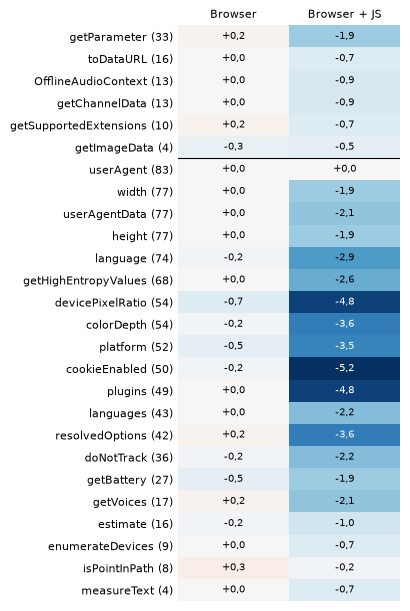

bedingung,alles_erlaubt,nur_cdp,alles_geblockt
methode,,,
WebGL.getParameter,33.4,33.6,31.5
canvas.toDataURL,15.9,15.9,15.2
webaudio.OfflineAudioContext,13.0,13.0,12.1
audio.getChannelData,12.8,12.8,11.9
WebGL.getSupportedExtensions,10.2,10.4,9.5
canvas2D.getImageData,3.6,3.3,3.1
Navigator.userAgent,83.0,83.0,83.0
Screen.width,77.0,77.0,75.1
Navigator.userAgentData,76.8,76.8,74.7


In [15]:
# Techniken: Anteil der Websites mit 3P-Aufruf je Methode, als Unterschied zu keiner Sperre in Prozentpunkten (nach Consent)
# Nur Methoden, die ohne Sperre auf mind. 2 % der Websites vorkommen. In Klammern: Anteil ohne Sperre
anteil = (auswahl[auswahl["punkt"] == "nach"].groupby(["methode", "bedingung"])["website"].nunique().unstack(fill_value=0)
          .reindex(columns=BEDINGUNGEN, fill_value=0) / len(panel) * 100)
anteil = anteil[anteil["alles_erlaubt"] >= 2]
info = METHODEN.set_index("methode").loc[anteil.index]
anteil = anteil.loc[info.assign(basis=anteil["alles_erlaubt"]).sort_values(["wertung", "basis"], ascending=[False, False]).index]
diff = anteil[BEDINGUNGEN[1:]].sub(anteil["alles_erlaubt"], axis=0)

grenze = max(abs(diff.values).max(), 1)
fig, ax = plt.subplots(figsize=(BREITE * 0.75, 0.2 * len(diff) + 0.8), layout="constrained")
ax.pcolormesh(diff.values, cmap="RdBu_r", vmin=-grenze, vmax=grenze) # rot = mehr mit Sperre, blau = weniger
for zeile, werte in enumerate(diff.values):
    for spalte, wert in enumerate(werte):
        ax.text(spalte + 0.5, zeile + 0.5, f"{wert:+.1f}".replace(".", ","), ha="center", va="center", fontsize=7,
                color="white" if abs(wert) > 0.6 * grenze else "black")
ax.set_xticks([0.5, 1.5], [KURZ[bedingung] for bedingung in BEDINGUNGEN[1:]])
ax.set_yticks([i + 0.5 for i in range(len(diff))], [f"{m.rpartition('.')[2]} ({anteil.loc[m, 'alles_erlaubt']:.0f})" for m in diff.index])
ax.invert_yaxis()
ax.xaxis.tick_top()
ax.tick_params(length=0)
for seite in ax.spines.values():
    seite.set_visible(False)
ax.axhline((info.loc[diff.index, "wertung"] == "stark").sum(), color="black", linewidth=0.8) # Trennlinie stark / schwach
speichern(fig, "techniken_veraenderung")
plt.show()
anteil.round(1)

**Techniken**
- Browser-Sperre: keine Methode ändert sich um mehr als 1 Prozentpunkt
- Browser + JS: fast alle Methoden etwas seltener (bis -5,2 Punkte bei cookieEnabled, -4,8 bei plugins und devicePixelRatio), keine wird häufiger
- Starke Techniken (Canvas, WebGL, Audio) jeweils höchstens 2 Punkte weniger: kein Ausweichen auf berechnete Merkmale

In [16]:
# Anbieter: Welche Quellen rufen mit Sperre häufiger bzw. seltener auf? (Browser + JS gegen keine Sperre, nach Consent)
# Je Quelle: auf wie vielen Websites sie vorkommt, auf wie vielen sie mit Sperre mehr bzw. weniger aufruft. Nur Quellen auf mind. 10 Websites
je_quelle = (auswahl[auswahl["punkt"] == "nach"].groupby(["quelle", "website", "bedingung"])["anzahl"].sum()
             .unstack(fill_value=0).reindex(columns=BEDINGUNGEN, fill_value=0))
veraenderung = je_quelle["alles_geblockt"] - je_quelle["alles_erlaubt"]
quellen = pd.DataFrame({"websites": veraenderung.groupby("quelle").size(),
                        "mehr": (veraenderung > 0).groupby("quelle").sum(),
                        "weniger": (veraenderung < 0).groupby("quelle").sum()})
quellen["netto"] = quellen["mehr"] - quellen["weniger"]
quellen = quellen[quellen["websites"] >= 10]
pd.concat([quellen.nlargest(8, "netto"), quellen.nsmallest(8, "netto")])

,websites,mehr,weniger,netto
quelle,,,,
facebook.net,152,78,35,43
google-analytics.com,71,37,8,29
google.com,54,18,1,17
trustarc.com,15,9,2,7
amazonaws.com,11,4,0,4
jsdelivr.net,26,4,1,3
adsafeprotected.com,11,6,4,2
cloudflare.com,21,4,2,2
googletagmanager.com,336,29,87,-58


**Anbieter**
- Mit Sperre mehr Aufrufe: facebook.net (auf 78 Websites mehr, auf 35 weniger), google-analytics.com (37 zu 8), google.com (18 zu 1). Das sind die Kandidaten für ein Ausweichen
- Mit Sperre weniger: googletagmanager.com (29 zu 87), Werbebörsen wie rubiconproject.com (0 zu 33) und pubmatic.com (0 zu 26)
- Vermutung: Werbe-Auktionen laufen ohne Cookie-IDs seltener an, einzelne Tracker fragen dafür mehr ab

In [17]:
# Ausweichen auf den Speicher? Anteil der Websites, auf denen 3P-Skripte localStorage/sessionStorage schreiben bzw. lesen (nach Consent)
# Storage zählt nicht als Fingerprinting, wäre aber ein zustandsbehafteter Ersatz für gesperrte Cookies
speicher = calls[calls["website"].isin(panel_menge) & (calls["partei"] == "3P") & (calls["kategorie"] == "Storage") & (calls["punkt"] == "nach")]
speicher_anteil = (speicher.groupby(["methode", "bedingung"])["website"].nunique().unstack(fill_value=0)
                   .reindex(columns=BEDINGUNGEN, fill_value=0) / len(panel) * 100)
speicher_aufrufe = speicher.groupby(["methode", "bedingung"])["anzahl"].sum().unstack(fill_value=0).reindex(columns=BEDINGUNGEN, fill_value=0)
print("Anteil der Websites (in Prozent):")
print(speicher_anteil.round(1))
print("Aufrufe insgesamt:")
speicher_aufrufe

Anteil der Websites (in Prozent):
bedingung                      alles_erlaubt  nur_cdp  alles_geblockt
methode                                                              
local/session storage.getItem           71.3     71.3            70.8
local/session storage.setItem           69.4     69.2            68.0
Aufrufe insgesamt:


bedingung,alles_erlaubt,nur_cdp,alles_geblockt
methode,,,
local/session storage.getItem,83113,84449,73318
local/session storage.setItem,23855,23743,22463


**Ausweichen auf den Speicher**
- Kein Ausweichen: 3P-Skripte schreiben auf 69,4 / 69,2 / 68,0 % der Websites in den Speicher
- Mit Browser + JS eher weniger Zugriffe (Lesen 73.318 statt 83.113)

In [18]:
# Reihenfolge der Besuche: Jede Website wurde in allen drei Bedingungen direkt nacheinander besucht, die Reihenfolge wechselt reihum
# Oben: wie oft jede Bedingung an 1., 2., 3. Stelle stand. Unten: Median der Aufrufe je Bedingung und Stelle
print(pd.crosstab(nach["bedingung"], nach["position"]).loc[BEDINGUNGEN])
pd.pivot_table(nach, index="bedingung", columns="position", values="anzahl", aggfunc="median").loc[BEDINGUNGEN]

position        1.0  2.0  3.0
bedingung                    
alles_erlaubt   188  175  215
nur_cdp         190  206  182
alles_geblockt  200  197  181


position,1.0,2.0,3.0
bedingung,,,
alles_erlaubt,146.5,238.0,137.0
nur_cdp,166.5,136.0,162.5
alles_geblockt,150.0,124.0,148.0


**Reihenfolge**
- Jede Bedingung stand ungefähr gleich oft an 1., 2. und 3. Stelle (175 bis 215 Websites)
- Die Mediane je Stelle schwanken (keine Sperre an 2. Stelle 238), weil an jeder Stelle andere Websites stehen. Ein klarer Reihenfolgeeffekt ist nicht zu sehen

In [19]:
# Consent je Bedingung: Klappt der Klick, und speichert das Consent-Tool die Entscheidung?
# Die JS-Sperre verwirft auch Cookies fremder Consent-Tools. Unterschiede hier würden den Vergleich der Bedingungen verzerren
(snap[snap["im_panel"]].groupby("bedingung")[["consent_klick", "consent_gespeichert"]].mean().loc[BEDINGUNGEN] * 100).round(1)

,consent_klick,consent_gespeichert
bedingung,,
alles_erlaubt,45.67474,29.065744
nur_cdp,45.155709,27.854671
alles_geblockt,42.214533,14.705882


**Consent je Bedingung**
- Der Klick klappt fast gleich oft (45,7 / 45,2 / 42,2 %)
- Gespeichert wird die Zustimmung mit Browser + JS nur halb so oft (14,7 statt 29,1 %): die JS-Sperre verwirft auch die Cookies fremder Consent-Tools
- Folge: Tracker, die auf die Zustimmung warten, laden seltener. Das erklärt den Rückgang der Aufrufe (siehe Robustheit)

## Statistik

- Aufrufe: Friedman über die drei Bedingungen, Wilcoxon paarweise mit Effektstärke r, Holm-Korrektur
- Anteil mit starkem Aufruf: Cochran-Q, McNemar paarweise
- Ausweichen auf localStorage: McNemar keine Sperre gegen Browser + JS

In [20]:
# Aufrufe je Website: Unterschied zwischen den Bedingungen? Dieselben Websites in allen drei, deshalb gepaarte Rangtests
# Effektstärke r = |z| / Wurzel(n), grob: 0,1 klein, 0,3 mittel, 0,5 groß
from scipy.stats import friedmanchisquare, wilcoxon
from statsmodels.stats.multitest import multipletests

f = friedmanchisquare(*[aufrufe[bedingung] for bedingung in BEDINGUNGEN])
print(f"Friedman = {f.statistic:.1f}, p = {f.pvalue:.4g}")
PAARE = [("alles_erlaubt", "nur_cdp"), ("alles_erlaubt", "alles_geblockt"), ("nur_cdp", "alles_geblockt")]
zeilen_wilcoxon = []
for a, b in PAARE:
    w = wilcoxon(aufrufe[a], aufrufe[b], method="approx")
    zeilen_wilcoxon.append({"vergleich": f"{KURZ[a]} -> {KURZ[b]}", "median_a": aufrufe[a].median(), "median_b": aufrufe[b].median(),
                            "p": w.pvalue, "r": abs(w.zstatistic) / len(aufrufe) ** 0.5})
test_aufrufe = pd.DataFrame(zeilen_wilcoxon)
test_aufrufe["p_holm"] = multipletests(test_aufrufe["p"], method="holm")[1]
test_aufrufe.round(4)

Friedman = 5.4, p = 0.06646


,vergleich,median_a,median_b,p,r,p_holm
0,keine Sperre -> Browser,154.5,154.0,0.7215,0.0148,0.7215
1,keine Sperre -> Browser + JS,154.5,141.0,0.0001,0.1584,0.0004
2,Browser -> Browser + JS,154.0,141.0,0.0006,0.1423,0.0013


**Test: Aufrufe**
- Friedman p = 0,07: über alle drei Bedingungen kein klarer Unterschied
- Keine Sperre -> Browser: 154,5 -> 154, p = 0,72, r = 0,01, kein Effekt
- Keine Sperre -> Browser + JS: 154,5 -> 141, p < 0,001 nach Holm, r = 0,16, kleiner Rückgang
- H2 (mehr Aufrufe mit Sperre) wird nicht gestützt

In [21]:
# Anteil mit starkem Aufruf: Cochran-Q über alle drei Bedingungen, McNemar exakt paarweise mit Holm-Korrektur
from statsmodels.stats.contingency_tables import cochrans_q, mcnemar

q = cochrans_q(stark.astype(int))
print(f"Cochran-Q = {q.statistic:.1f}, p = {q.pvalue:.4f}")
print("Anteil mit starkem Aufruf (in Prozent):", (stark.mean() * 100).round(1).to_dict())
zeilen_mcnemar = []
for a, b in PAARE:
    # Vierfeldertafel: Zeilen = Bedingung a stark ja/nein, Spalten = Bedingung b stark ja/nein
    tafel = pd.crosstab(stark[a], stark[b]).reindex(index=[False, True], columns=[False, True], fill_value=0)
    zeilen_mcnemar.append({"vergleich": f"{KURZ[a]} -> {KURZ[b]}", "nur_b_stark": tafel.loc[False, True],
                           "nur_a_stark": tafel.loc[True, False], "p": mcnemar(tafel, exact=True).pvalue})
test_stark = pd.DataFrame(zeilen_mcnemar)
test_stark["p_holm"] = multipletests(test_stark["p"], method="holm")[1]
test_stark.round(4)

Cochran-Q = 15.1, p = 0.0005
Anteil mit starkem Aufruf (in Prozent): {'alles_erlaubt': 36.7, 'nur_cdp': 36.7, 'alles_geblockt': 34.8}


,vergleich,nur_b_stark,nur_a_stark,p,p_holm
0,keine Sperre -> Browser,1,1,1.0000,1.0000
1,keine Sperre -> Browser + JS,2,13,0.0074,0.0222
2,Browser -> Browser + JS,2,13,0.0074,0.0222


**Test: Anteil mit starkem Aufruf**
- 36,7 / 36,7 / 34,8 % der Websites
- Mit Browser + JS verlieren 13 Websites den starken Aufruf, 2 kommen dazu (p = 0,02 nach Holm)

In [22]:
# Ausweichen auf localStorage: schreiben 3P-Skripte mit Sperre häufiger in den Speicher? McNemar keine Sperre gegen Browser + JS
schreibt = (speicher[speicher["methode"] == "local/session storage.setItem"].groupby(["website", "bedingung"]).size().unstack()
            .reindex(index=panel, columns=BEDINGUNGEN).notna())
tafel = pd.crosstab(schreibt["alles_erlaubt"], schreibt["alles_geblockt"]).reindex(index=[False, True], columns=[False, True], fill_value=0)
print(f"nur mit Sperre: {tafel.loc[False, True]}, nur ohne Sperre: {tafel.loc[True, False]}, p = {mcnemar(tafel, exact=True).pvalue:.4f}")

nur mit Sperre: 1, nur ohne Sperre: 9, p = 0.0215


**Test: Speicher**
- Mit Sperre schreibt 1 Website zusätzlich in den Speicher, 9 nicht mehr (p = 0,02): eher weniger statt mehr

# Nebenfakten

- Auswahl des Panels: Verteilung auf die Rangbereiche
- Robustheit: nur die Websites der FF1-Stichprobe (500 aus der Thesis), nur Websites mit gleichem Banner-Klick in allen Bedingungen

In [23]:
# Auswahl des Panels prüfen: Sind die Rangbereiche im Panel noch gleich stark vertreten?
# Rang aus der Tranco-Liste, Grenzen der Rangbereiche aus der Konfiguration (wie beim Ziehen der Stichprobe, utils/tranco_worker.py)
import csv
from itertools import islice

GRENZEN = configs["alles_erlaubt"][-1]["rank_bands"]
with open(configs["alles_erlaubt"][-1]["path_to_webpages"], encoding="utf-8") as datei:
    rang = {domain: int(platz) for platz, domain in islice(csv.reader(datei), GRENZEN[-1])}

def rangbereich(website):
    platz = rang[website.removeprefix("https://")]
    return next(bereich for bereich, grenze in enumerate(GRENZEN, 1) if platz <= grenze)

for name, liste in {"Stichprobe": websites, "vollständig": vollstaendig, "Panel": panel}.items():
    zaehler = Counter(rangbereich(website) for website in liste)
    print(f"{name:12s} n={len(liste):3d}  je Rangbereich:", {bereich: zaehler[bereich] for bereich in range(1, len(GRENZEN) + 1)})

Stichprobe   n=1000  je Rangbereich: {1: 250, 2: 250, 3: 250, 4: 250}
vollständig  n=759  je Rangbereich: {1: 173, 2: 188, 3: 195, 4: 203}
Panel        n=578  je Rangbereich: {1: 123, 2: 145, 3: 144, 4: 166}


**Rangbereiche**
- Panel 578 von 1000 Websites, der Bereich der Top 1000 ist etwas schwächer vertreten (123 gegen 166 im Bereich 4)

In [24]:
# Robustheit: Hält das Ergebnis (Wilcoxon keine Sperre gegen Browser + JS) auch für Teilgruppen?
# FF1-Stichprobe: die 500 Websites, auf die sich die Thesis bezieht (FF2 lief mit 1000)
# Consent: Die JS-Sperre verwirft auch Cookies fremder Consent-Tools. Ohne Klick bzw. bei gleich gespeichertem Consent fällt dieser Effekt weg
# Browser-Sperre gegriffen: mit Sperre keine unpartitionierten 3P-Cookies (vgl. Kontrolle der Sperren)
ff1_websites = {json.loads(line).get("website") for line in open("results/Forschungsfrage 1/ff1_live.jsonl", encoding="utf-8")}
panel_snap = snap[snap["im_panel"]]
klick = panel_snap.pivot(index="website", columns="bedingung", values="consent_klick")
gespeichert = panel_snap.pivot(index="website", columns="bedingung", values="consent_gespeichert")
cookie_quellen = panel_snap.pivot(index="website", columns="bedingung", values="cookie_quellen_3p_nach")
teilgruppen = {
    "Panel": aufrufe.index,
    "nur FF1-Stichprobe": aufrufe.index.intersection(list(ff1_websites)),
    "kein Banner-Klick": klick.index[~klick.any(axis=1)],
    "Consent gleich gespeichert": gespeichert.index[gespeichert.nunique(axis=1) == 1],
    "Browser-Sperre gegriffen": cookie_quellen.index[(cookie_quellen["nur_cdp"] == 0) & (cookie_quellen["alles_geblockt"] == 0)],
}
for name, teilgruppe in teilgruppen.items():
    teil = aufrufe.loc[teilgruppe]
    w = wilcoxon(teil["alles_erlaubt"], teil["alles_geblockt"], method="approx")
    print(f"{name:28s} n={len(teil):3d}  Median {teil['alles_erlaubt'].median():6.1f} -> {teil['alles_geblockt'].median():6.1f}  "
          f"mehr {(teil['alles_geblockt'] > teil['alles_erlaubt']).mean():.0%}  weniger {(teil['alles_geblockt'] < teil['alles_erlaubt']).mean():.0%}  "
          f"p={w.pvalue:.4f}  r={abs(w.zstatistic) / len(teil) ** 0.5:.2f}")

Panel                        n=578  Median  154.5 ->  141.0  mehr 23%  weniger 28%  p=0.0001  r=0.16
nur FF1-Stichprobe           n=292  Median  172.5 ->  142.5  mehr 22%  weniger 30%  p=0.0010  r=0.19
kein Banner-Klick            n=314  Median   51.5 ->   50.5  mehr 16%  weniger 13%  p=0.7982  r=0.01
Consent gleich gespeichert   n=494  Median  117.5 ->  113.0  mehr 23%  weniger 21%  p=0.5242  r=0.03
Browser-Sperre gegriffen     n=436  Median   83.5 ->   74.0  mehr 19%  weniger 23%  p=0.0009  r=0.16


**Robustheit**
- FF1-Stichprobe (292 Websites): gleiches Bild, Rückgang 172,5 -> 142,5
- Kein Banner-Klick (314) und Consent gleich gespeichert (494): kein Unterschied mehr (p = 0,80 bzw. 0,52, r höchstens 0,03)
- Browser-Sperre gegriffen (436): Rückgang bleibt (83,5 -> 74), dort wirkt der Consent-Effekt weiter
- Fazit: Der Rückgang mit JS-Sperre ist ein Consent-Effekt. Die Sperre verhindert, dass Consent-Tools die Zustimmung speichern. Fingerprinting als Ausweichstrategie zeigt sich nicht

In [25]:
import numpy as np
from scipy.stats import pearsonr, spearmanr, wilcoxon
from statsmodels.stats.contingency_tables import mcnemar
from statsmodels.stats.multitest import multipletests


def tests(tab_aufrufe, tab_stark, titel):
    # Gleiche Tests wie im Notebook: Wilcoxon mit r = |z| / Wurzel(n), McNemar exakt, Holm ueber die drei Paare
    zeilen = []
    for a, b in PAARE:
        w = wilcoxon(tab_aufrufe[a], tab_aufrufe[b], method="approx")
        tafel = pd.crosstab(tab_stark[a], tab_stark[b]).reindex(index=[False, True], columns=[False, True], fill_value=0)
        zeilen.append({"vergleich": f"{KURZ[a]} -> {KURZ[b]}", "median_a": tab_aufrufe[a].median(), "median_b": tab_aufrufe[b].median(),
                       "mehr": (tab_aufrufe[b] > tab_aufrufe[a]).sum(), "weniger": (tab_aufrufe[b] < tab_aufrufe[a]).sum(),
                       "p_wilcoxon": w.pvalue, "r": abs(w.zstatistic) / len(tab_aufrufe) ** 0.5,
                       "stark_a": tab_stark[a].mean() * 100, "stark_b": tab_stark[b].mean() * 100,
                       "nur_b_stark": tafel.loc[False, True], "nur_a_stark": tafel.loc[True, False],
                       "p_mcnemar": mcnemar(tafel, exact=True).pvalue})
    tabelle = pd.DataFrame(zeilen)
    tabelle["p_wilcoxon_holm"] = multipletests(tabelle["p_wilcoxon"], method="holm")[1]
    tabelle["p_mcnemar_holm"] = multipletests(tabelle["p_mcnemar"], method="holm")[1]
    print(f"\n== {titel} (n = {len(tab_aufrufe)})")
    print(tabelle.round(4).to_string())


print("== 0. Messpunkt 2 (nach Consent): alle Werte fuer Tabelle tab:FF2Tests in einer Ausgabe")
tests(aufrufe, stark, "Messpunkt 2")

print("\n== 1. Messpunkt 1 (vor Consent): gleiche Tests. Hier wirkt der Consent-Unterschied der JS-Sperre noch nicht")
vor = je_website[je_website["punkt"] == "vor"]
aufrufe_vor = vor.pivot(index="website", columns="bedingung", values="anzahl")[BEDINGUNGEN]
stark_vor = vor.pivot(index="website", columns="bedingung", values="stark")[BEDINGUNGEN]
tests(aufrufe_vor, stark_vor, "Messpunkt 1")

print("\n== 2. Websites, denen die Browser-Sperre wirklich Cookies entzieht")
# Ohne Sperre mind. eine Quelle mit unpartitionierten 3P-Cookies, mit Browser-Sperre und mit Browser + JS keine
panel_snap = snap[snap["im_panel"]]
quellen_3p = panel_snap.pivot(index="website", columns="bedingung", values="cookie_quellen_3p_nach")[BEDINGUNGEN]
entzogen = quellen_3p.index[(quellen_3p["alles_erlaubt"] > 0) & (quellen_3p["nur_cdp"] == 0) & (quellen_3p["alles_geblockt"] == 0)]
print("Websites mit 3P-Cookies ohne Sperre:", int((quellen_3p["alles_erlaubt"] > 0).sum()),
      "| davon unter beiden Sperren ohne 3P-Cookies:", len(entzogen))
print("Websites mit 3P-Cookies trotz Browser-Sperre:", int((quellen_3p["nur_cdp"] > 0).sum()))
tests(aufrufe.loc[entzogen], stark.loc[entzogen], "Cookies entzogen, Messpunkt 2")

print("\n== 3. Korrelation: Je mehr Cookie-Quellen die Browser-Sperre entzieht, desto mehr Aufrufe? (Pearson, Betreuer 14.08.)")
# Nur Websites mit 3P-Cookies ohne Sperre. x = Quellen ohne Sperre minus Quellen mit Browser-Sperre
# y = Veraenderung der Aufrufe auf log(1 + x) wie in FF1 (Browser-Sperre minus keine Sperre). H2 erwartet r > 0
mit_cookies = quellen_3p.index[quellen_3p["alles_erlaubt"] > 0]
x = quellen_3p.loc[mit_cookies, "alles_erlaubt"] - quellen_3p.loc[mit_cookies, "nur_cdp"]
y = np.log1p(aufrufe.loc[mit_cookies, "nur_cdp"]) - np.log1p(aufrufe.loc[mit_cookies, "alles_erlaubt"])
p = pearsonr(x, y)
s = spearmanr(x, y)
print(f"n = {len(x)}, Pearson r = {p.statistic:.2f} (p = {p.pvalue:.3f}), Spearman = {s.statistic:.2f} (p = {s.pvalue:.3f})")
print("Entzogene Quellen je Website: Median", x.median(), "| Maximum", x.max())
# Gegenprobe Zusammenhang statt Ersatz: ohne Sperre, Cookie-Quellen gegen Aufrufe je Website (alle Panel-Websites)
p0 = pearsonr(np.log1p(quellen_3p["alles_erlaubt"]), np.log1p(aufrufe["alles_erlaubt"]))
print(f"Ohne Sperre: log(1 + Cookie-Quellen) gegen log(1 + Aufrufe), Pearson r = {p0.statistic:.2f} (p = {p0.pvalue:.3g}), n = {len(aufrufe)}")

print("\n== 4. Consent gespeichert: auf wie vielen Websites aendert die JS-Sperre das Ergebnis?")
gespeichert = panel_snap.pivot(index="website", columns="bedingung", values="consent_gespeichert")[BEDINGUNGEN]
print("gespeichert ohne Sperre, nicht mit Browser + JS:", int((gespeichert["alles_erlaubt"] & ~gespeichert["alles_geblockt"]).sum()),
      "| umgekehrt:", int((~gespeichert["alles_erlaubt"] & gespeichert["alles_geblockt"]).sum()))

print("\n== 5. Aufrufe ohne 1P/3P-Zuordnung (partei unbekannt), Panel, Messpunkt 2")
c = calls[calls["website"].isin(set(panel)) & (calls["punkt"] == "nach") & calls["zaehlt"]]
print(c.groupby(["bedingung", "partei"])["anzahl"].sum().unstack(fill_value=0).loc[BEDINGUNGEN])

print("\n== 6. Fehlerzeilen: wie oft gleich in allen drei Bedingungen?")
fehler = pd.DataFrame({b: {w: art(z) == "fehler" for w, z in letzte[b].items()} for b in BEDINGUNGEN})
print("Fehler in allen drei:", int(fehler.all(axis=1).sum()), "| in genau einer oder zwei:", int((fehler.any(axis=1) & ~fehler.all(axis=1)).sum()))

print("\n== 7. Consent nachweisen: Eintrag gespeichert ODER TCF meldet useractioncomplete (nicht jedes Consent-Tool schreibt einen passenden Eintrag oder hat TCF)")
# tcf_status kommt aus consent_check (core/consent.py), die JS-Sperre betrifft die TCF-Schnittstelle der Seite nicht
tcf = pd.DataFrame({b: {w: (letzte[b][w]["stats_nach_consent"].get("consent_check") or {}).get("tcf_status") for w in panel} for b in BEDINGUNGEN})
tcf_fertig = tcf == "useractioncomplete"
belegt = tcf_fertig | gespeichert.reindex(index=panel, columns=BEDINGUNGEN).fillna(False).astype(bool)
print("Websites mit TCF-Schnittstelle (je Bedingung):", tcf.notna().sum().to_dict())
print("TCF useractioncomplete (Prozent):", (tcf_fertig.mean() * 100).round(1).to_dict())
print("Zustimmung belegt (Prozent):", (belegt.mean() * 100).round(1).to_dict())
print("Belegt ohne Sperre, nicht mit Browser + JS:", int((belegt["alles_erlaubt"] & ~belegt["alles_geblockt"]).sum()), "| umgekehrt:", int((~belegt["alles_erlaubt"] & belegt["alles_geblockt"]).sum()))

print("\n== 8. Sitzt der Rueckgang dort, wo der Beleg verloren geht? Wilcoxon keine Sperre -> Browser + JS je Gruppe (Messpunkt 2)")
gruppen = {
    "Beleg geht unter JS-Sperre verloren": belegt.index[belegt["alles_erlaubt"] & ~belegt["alles_geblockt"]],
    "Beleg bleibt in beiden": belegt.index[belegt["alles_erlaubt"] & belegt["alles_geblockt"]],
    "kein Beleg in beiden (Tool unbekannt oder kein Banner)": belegt.index[~belegt["alles_erlaubt"] & ~belegt["alles_geblockt"]],
}
for name, gruppe in gruppen.items():
    teil = aufrufe.loc[gruppe]
    w = wilcoxon(teil["alles_erlaubt"], teil["alles_geblockt"], method="approx")
    print(f"{name:55s} n={len(teil):3d}  Median {teil['alles_erlaubt'].median():6.1f} -> {teil['alles_geblockt'].median():6.1f}  "
          f"mehr {(teil['alles_geblockt'] > teil['alles_erlaubt']).mean():.0%}  weniger {(teil['alles_geblockt'] < teil['alles_erlaubt']).mean():.0%}  "
          f"p={w.pvalue:.4f}  r={abs(w.zstatistic) / len(teil) ** 0.5:.2f}")


== 0. Messpunkt 2 (nach Consent): alle Werte fuer Tabelle tab:FF2Tests in einer Ausgabe

== Messpunkt 2 (n = 578)
                      vergleich  median_a  median_b  mehr  weniger  p_wilcoxon       r  stark_a  stark_b  nur_b_stark  nur_a_stark  p_mcnemar  p_wilcoxon_holm  p_mcnemar_holm
0       keine Sperre -> Browser     154.5     154.0    97      113      0.7215  0.0148  36.6782  36.6782            1            1     1.0000           0.7215          1.0000
1  keine Sperre -> Browser + JS     154.5     141.0   134      164      0.0001  0.1584  36.6782  34.7751            2           13     0.0074           0.0004          0.0222
2       Browser -> Browser + JS     154.0     141.0   133      164      0.0006  0.1423  36.6782  34.7751            2           13     0.0074           0.0013          0.0222

== 1. Messpunkt 1 (vor Consent): gleiche Tests. Hier wirkt der Consent-Unterschied der JS-Sperre noch nicht

== Messpunkt 1 (n = 578)
                      vergleich  median_a  median_b